In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("C:\\Users\\macha\\Downloads\\archive (6)\WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.shape

(7043, 21)

In [4]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [5]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [6]:
df.describe()


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [8]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [9]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [10]:
df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [11]:
pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [12]:
df.groupby('Churn')['tenure'].mean()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

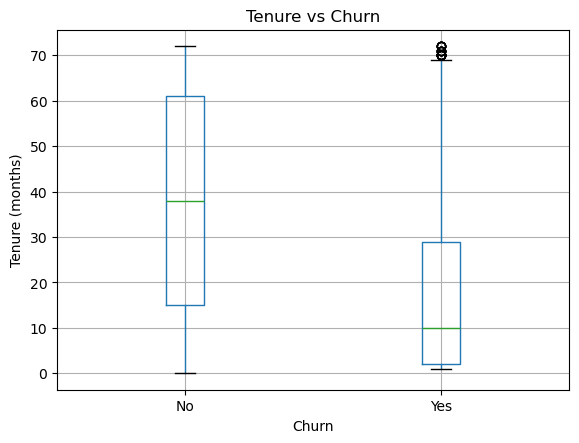

In [13]:
df.boxplot(column="tenure", by="Churn")
plt.title("Tenure vs Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Tenure (months)")
plt.show()

In [14]:
df.groupby('Churn')['MonthlyCharges'].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

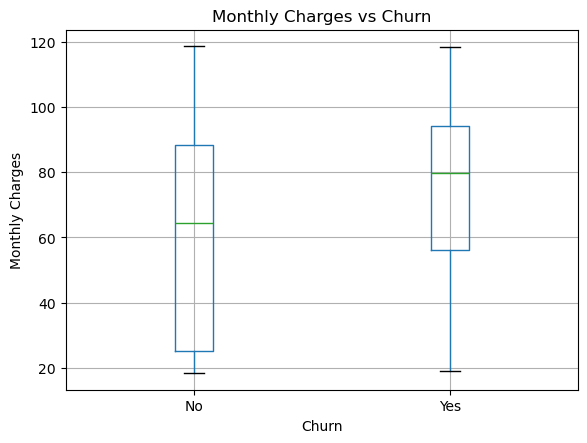

In [15]:
df.boxplot(column="MonthlyCharges", by="Churn")

plt.title("Monthly Charges vs Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

In [16]:
df['InternetService'].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [17]:
pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
)*100

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


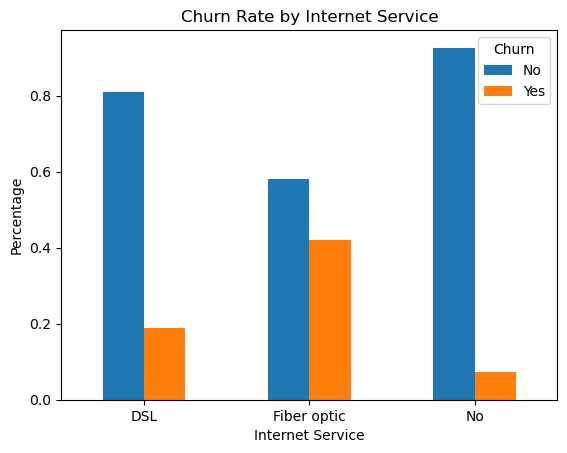

In [18]:
pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
).plot(kind='bar')
plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.show()

In [19]:
df['PaymentMethod'].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [20]:
pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize="index"
)*100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


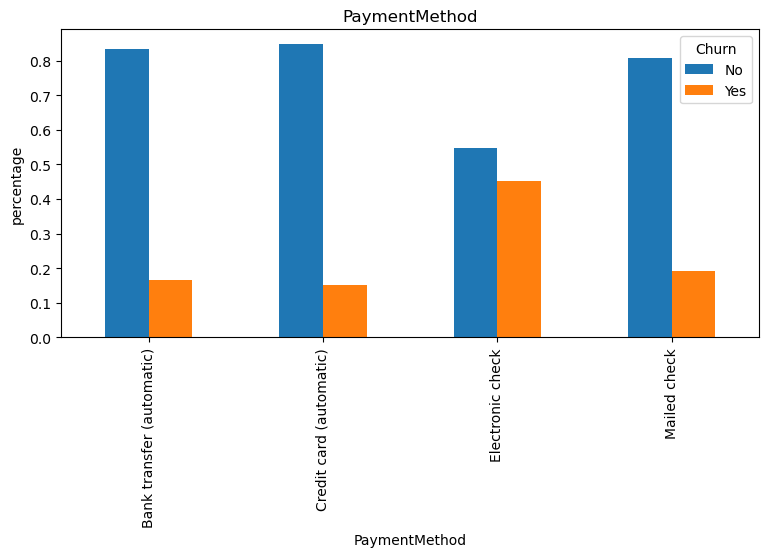

In [21]:
pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
).plot(kind="bar", figsize=(9,4))
plt.xlabel("PaymentMethod")
plt.ylabel("percentage")
plt.title("PaymentMethod")
plt.show()

In [22]:
pd.crosstab(
    df['SeniorCitizen'],
    df['Churn'],
    normalize='index'
)*100

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


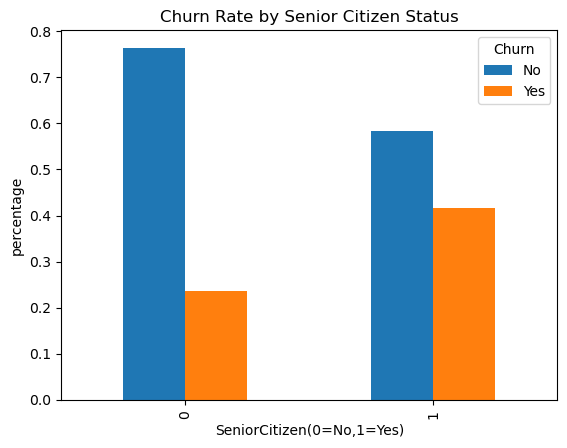

In [23]:
pd.crosstab(
    df['SeniorCitizen'],
    df['Churn'],
    normalize='index'
).plot(kind="bar")
plt.title("Churn Rate by Senior Citizen Status")
plt.xlabel("SeniorCitizen(0=No,1=Yes)")
plt.ylabel("percentage")
plt.show()


In [24]:
df["TotalCharges"].dtype

dtype('O')

In [25]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [26]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [27]:
df["TotalCharges"]

0         29.85
1       1889.50
2        108.15
3       1840.75
4        151.65
         ...   
7038    1990.50
7039    7362.90
7040     346.45
7041     306.60
7042    6844.50
Name: TotalCharges, Length: 7043, dtype: float64

In [28]:
df["TotalCharges"]=df["TotalCharges"].fillna(df["TotalCharges"].mean())

In [29]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [30]:
df = df.drop("customerID", axis=1)

In [31]:
df["Churn"]=df["Churn"].map({"Yes":1,"No":0})

In [32]:
df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [33]:
X=df.drop("Churn",axis=1)
y=df["Churn"]

In [34]:
print(X)

      gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0     Female              0     Yes         No       1           No   
1       Male              0      No         No      34          Yes   
2       Male              0      No         No       2          Yes   
3       Male              0      No         No      45           No   
4     Female              0      No         No       2          Yes   
...      ...            ...     ...        ...     ...          ...   
7038    Male              0     Yes        Yes      24          Yes   
7039  Female              0     Yes        Yes      72          Yes   
7040  Female              0     Yes        Yes      11           No   
7041    Male              1     Yes         No       4          Yes   
7042    Male              0      No         No      66          Yes   

         MultipleLines InternetService OnlineSecurity OnlineBackup  \
0     No phone service             DSL             No          Yes   
1      

In [35]:
print(y)

0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: Churn, Length: 7043, dtype: int64


In [36]:
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Target values:", y.unique())

X shape: (7043, 19)
y shape: (7043,)
Target values: [0 1]


In [37]:
X.select_dtypes(include="object").columns

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')

In [38]:
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

In [39]:
print(X_encoded)

      SeniorCitizen  tenure  MonthlyCharges  TotalCharges  gender_Male  \
0                 0       1           29.85         29.85            0   
1                 0      34           56.95       1889.50            1   
2                 0       2           53.85        108.15            1   
3                 0      45           42.30       1840.75            1   
4                 0       2           70.70        151.65            0   
...             ...     ...             ...           ...          ...   
7038              0      24           84.80       1990.50            1   
7039              0      72          103.20       7362.90            0   
7040              0      11           29.60        346.45            0   
7041              1       4           74.40        306.60            1   
7042              0      66          105.65       6844.50            1   

      Partner_Yes  Dependents_Yes  PhoneService_Yes  \
0               1               0                 0   
1

In [40]:
print("Original X shape:", X.shape)
print("Encoded X shape:", X_encoded.shape)

X_encoded.head()

Original X shape: (7043, 19)
Encoded X shape: (7043, 30)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


In [41]:
from sklearn.model_selection import train_test_split

In [42]:
X_train,X_test,y_train,y_test=train_test_split(X_encoded,y,test_size=0.2,random_state=42)

In [43]:
print(X_train)

      SeniorCitizen  tenure  MonthlyCharges  TotalCharges  gender_Male  \
2142              0      21           64.85   1336.800000            0   
1623              0      54           97.20   5129.450000            0   
6074              0       1           23.45     23.450000            1   
1362              0       4           70.20    237.950000            1   
6754              0       0           61.90   2283.300441            1   
...             ...     ...             ...           ...          ...   
3772              0       1           95.00     95.000000            1   
5191              0      23           91.10   2198.300000            0   
5226              0      12           21.15    306.050000            1   
5390              1      12           99.45   1200.150000            1   
860               0      26           19.80    457.300000            1   

      Partner_Yes  Dependents_Yes  PhoneService_Yes  \
2142            0               1                 1   
1

In [44]:
print(X_test)

      SeniorCitizen  tenure  MonthlyCharges  TotalCharges  gender_Male  \
185               0       1           24.80         24.80            0   
2715              0      41           25.25        996.45            1   
3825              0      52           19.35       1031.70            0   
1807              0       1           76.35         76.35            0   
132               0      67           50.55       3260.10            1   
...             ...     ...             ...           ...          ...   
6366              0      64           68.30       4378.80            0   
315               0      51          110.05       5686.40            1   
2439              0      17           19.90        329.75            1   
5002              0      69           43.95       2960.10            0   
1161              0       1           31.35         31.35            1   

      Partner_Yes  Dependents_Yes  PhoneService_Yes  \
185             1               0                 0   
2

In [45]:
print(y_train)

2142    0
1623    0
6074    1
1362    1
6754    0
       ..
3772    1
5191    0
5226    0
5390    1
860     0
Name: Churn, Length: 5634, dtype: int64


In [46]:
print(y_test)

185     1
2715    0
3825    0
1807    1
132     0
       ..
6366    0
315     0
2439    0
5002    0
1161    1
Name: Churn, Length: 1409, dtype: int64


In [47]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 30)
X_test: (1409, 30)
y_train: (5634,)
y_test: (1409,)


In [48]:
print("Training churn distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training churn distribution:
Churn
0    73.446929
1    26.553071
Name: proportion, dtype: float64

Testing churn distribution:
Churn
0    73.527324
1    26.472676
Name: proportion, dtype: float64


In [49]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


In [50]:
model=LogisticRegression(max_iter=1000)

In [51]:
model.fit(X_train,y_train)

C:\Users\macha\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [52]:
y_pred=model.predict(X_test)

In [53]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8211497515968772
              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.69      0.60      0.64       373

    accuracy                           0.82      1409
   macro avg       0.77      0.75      0.76      1409
weighted avg       0.82      0.82      0.82      1409



Confusion Matrix:
[[933 103]
 [149 224]]


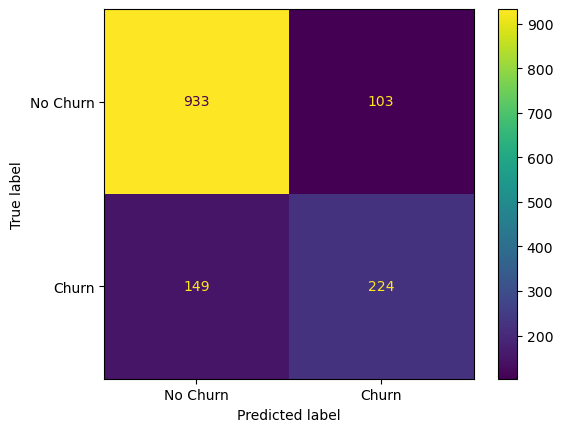

In [54]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.show()

In [55]:
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, dt_pred))
print("\nClassification Report:")
print(classification_report(y_test, dt_pred, zero_division=0))

Decision Tree Accuracy: 0.8062455642299503

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.93      0.88      1036
           1       0.70      0.46      0.56       373

    accuracy                           0.81      1409
   macro avg       0.77      0.70      0.72      1409
weighted avg       0.80      0.81      0.79      1409



In [56]:
knn_model=KNeighborsClassifier(
    n_neighbors=3
)
knn_model.fit(X_train,y_train)
knn_pred=knn_model.predict(X_test)
print("KNeighbors Accuracy:",accuracy_score(y_test,knn_pred))
print("\nccClassification Report:")
print(classification_report(y_test, knn_pred, zero_division=0))

KNeighbors Accuracy: 0.7672107877927609

ccClassification Report:
              precision    recall  f1-score   support

           0       0.82      0.87      0.85      1036
           1       0.57      0.49      0.52       373

    accuracy                           0.77      1409
   macro avg       0.70      0.68      0.69      1409
weighted avg       0.76      0.77      0.76      1409



In [57]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))
print("\nClassification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))


Random Forest Accuracy: 0.7984386089425124

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.92      0.87      1036
           1       0.67      0.47      0.55       373

    accuracy                           0.80      1409
   macro avg       0.75      0.69      0.71      1409
weighted avg       0.79      0.80      0.79      1409



In [58]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

models = {
    "Logistic Regression": (y_pred),
    "Decision Tree": (dt_pred),
    "KNN": (knn_pred),
    "Random Forest": (rf_pred)
}

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Churn Precision": precision_score(y_test, predictions, zero_division=0),
        "Churn Recall": recall_score(y_test, predictions, zero_division=0),
        "Churn F1": f1_score(y_test, predictions, zero_division=0)
    })

results_df = pd.DataFrame(results)
print(results_df.round(3).to_string(index=False))


              Model  Accuracy  Churn Precision  Churn Recall  Churn F1
Logistic Regression     0.821            0.685         0.601     0.640
      Decision Tree     0.806            0.705         0.461     0.558
                KNN     0.767            0.571         0.485     0.525
      Random Forest     0.798            0.672         0.466     0.551


In [59]:

from sklearn.model_selection import GridSearchCV

param_grid = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5]
}

dt = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

grid_search = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1:", round(grid_search.best_score_, 3))


Best parameters: {'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 2}
Best cross-validation F1: 0.612


Tuned Decision Tree Accuracy: 0.745

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.91      0.73      0.81      1036
       Churn       0.51      0.79      0.62       373

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.75      0.76      1409



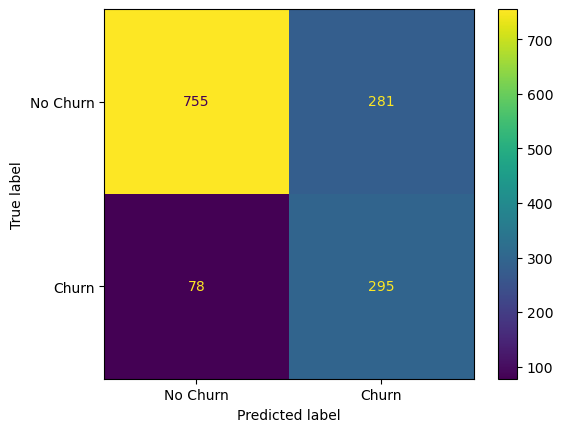

In [60]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

best_dt_model = grid_search.best_estimator_

best_dt_pred = best_dt_model.predict(X_test)

print("Tuned Decision Tree Accuracy:",
      round(accuracy_score(y_test, best_dt_pred), 3))

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_dt_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

cm = confusion_matrix(y_test, best_dt_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
).plot()

plt.show()


In [61]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

models = {
    "Logistic Regression": y_pred,
    "Decision Tree": dt_pred,
    "KNN": knn_pred,
    "Random Forest": rf_pred,
    "Tuned Decision Tree": best_dt_pred
}

results = []

for name, pred in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Churn Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Churn Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "Churn F1": f1_score(
            y_test, pred, zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)

print(
    comparison_df
    .sort_values("Churn F1", ascending=False)
    .round(3)
    .to_string(index=False)
)


              Model  Accuracy  Churn Precision  Churn Recall  Churn F1
Logistic Regression     0.821            0.685         0.601     0.640
Tuned Decision Tree     0.745            0.512         0.791     0.622
      Decision Tree     0.806            0.705         0.461     0.558
      Random Forest     0.798            0.672         0.466     0.551
                KNN     0.767            0.571         0.485     0.525


In [62]:

import joblib

joblib.dump(model, "customer_churn_model.pkl")

print("Model saved successfully!")


Model saved successfully!
